In [1]:
! pip install -q optuna
! pip install -q emoji

In [2]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
import optuna
import ast
import re
import emoji
from transformers.utils import logging as hf_logging
import gc
import shutil
import random
import math
import html
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification, EarlyStoppingCallback, TrainerCallback, set_seed
from scipy.special import softmax
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score, classification_report
import datasets
import optuna
from huggingface_hub.utils import disable_progress_bars
from transformers.trainer_callback import PrinterCallback, ProgressCallback
from transformers.utils import logging as hf_logging
 
hf_logging.set_verbosity_error()          # laporan load model, warning transformers
hf_logging.disable_progress_bar()         # "Writing model shards", "Loading weights"
disable_progress_bars()                   # progress bar download dari Hugging Face Hub
datasets.disable_progress_bars()          # progress bar "Map"
optuna.logging.set_verbosity(optuna.logging.WARNING)   # log bawaan Optuna per trial

In [3]:
df = pd.read_csv("/kaggle/input/datasets/audreytheodoraphang/dataset-thesis/dataset_exploded_with_metadata.csv")

In [4]:
df.head(1)

,Unnamed: 0,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,threat_incitement_to_violence,insults,identity_attack,...,ethnicity,religion,disability,lgbt,gender,age,domisili,pendidikan terakhir,status pekerjaan,president vote leaning
0,0,Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,...,Minang,Islam,yes,no,F,27,Padang,Sarjana (S1),Bekerja,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51970 entries, 0 to 51969
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0                     51970 non-null  int64 
 1   text                           51970 non-null  object
 2   topic                          51970 non-null  object
 3   is_noise_or_spam_text          51970 non-null  int64 
 4   toxicity                       51970 non-null  int64 
 5   polarized                      51970 non-null  int64 
 6   profanity_obscenity            51970 non-null  int64 
 7   threat_incitement_to_violence  51970 non-null  int64 
 8   insults                        51970 non-null  int64 
 9   identity_attack                51970 non-null  int64 
 10  sexually_explicit              51970 non-null  int64 
 11  key                            51970 non-null  object
 12  cleaned_text                   51970 non-null  object
 13  p

In [6]:
df = df.drop(columns = ['Unnamed: 0', 'key'])

In [7]:
df['is_noise_or_spam_text'].value_counts()

is_noise_or_spam_text
0    50767
1     1203
Name: count, dtype: int64

In [8]:
df['is_valid'].value_counts()

is_valid
True     51950
False       20
Name: count, dtype: int64

In [9]:
df_main = df[df['is_noise_or_spam_text'] == 0]
df_main = df_main[df_main['is_valid'] == 1]
df_main = df_main.dropna()
df_main.isnull().sum()

text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
cleaned_text                     0
processed_text                   0
is_valid                         0
ethnicity                        0
religion                         0
disability                       0
lgbt                             0
gender                           0
age                              0
domisili                         0
pendidikan terakhir              0
status pekerjaan                 0
president vote leaning           0
dtype: int64

In [10]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50748 entries, 0 to 51969
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   text                           50748 non-null  object
 1   topic                          50748 non-null  object
 2   is_noise_or_spam_text          50748 non-null  int64 
 3   toxicity                       50748 non-null  int64 
 4   polarized                      50748 non-null  int64 
 5   profanity_obscenity            50748 non-null  int64 
 6   threat_incitement_to_violence  50748 non-null  int64 
 7   insults                        50748 non-null  int64 
 8   identity_attack                50748 non-null  int64 
 9   sexually_explicit              50748 non-null  int64 
 10  cleaned_text                   50748 non-null  object
 11  processed_text                 50748 non-null  object
 12  is_valid                       50748 non-null  bool  
 13  ethnic

In [11]:
EMOJI_LANG = "id"
# Emoticon teks -> kata. Hanya dicocokkan kalau berdiri sendiri (diapit spasi),
# supaya tidak salah tangkap di tengah kata.
emoticon_dict = {
    ":)": "senyum", ":-)": "senyum", "(:": "senyum", ":]": "senyum", "=)": "senyum",
    ":d": "tertawa", ":-d": "tertawa", "xd": "tertawa", "wkwk": "tertawa",
    ":(": "sedih", ":-(": "sedih", "):": "sedih", ":'(": "menangis",
    ";)": "berkedip", ";-)": "berkedip",
    ":p": "menjulurkan lidah", ":-p": "menjulurkan lidah",
    ":o": "terkejut", ":-o": "terkejut",
    ":/": "ragu", ":-/": "ragu",
    ">:(": "marah", "-_-": "kesal", "<3": "cinta", "</3": "patah hati",
}
_emoticon_re = re.compile(
    r"(?<!\S)(" + "|".join(re.escape(k) for k in sorted(emoticon_dict, key=len, reverse=True)) + r")(?!\S)",
    flags=re.IGNORECASE,
)


def convert_emoticons(text):
    return _emoticon_re.sub(lambda m: f" {emoticon_dict[m.group(1).lower()]} ", text)


def convert_emojis(text, language=EMOJI_LANG):
    # 😂 -> "wajah gembira berurai air mata"
    text = emoji.demojize(text, delimiters=("<<", ">>"), language=language)
    return re.sub(r"<<([^<>]+)>>", lambda m: " " + m.group(1).replace("_", " ") + " ", text)


def normalize_slang(text):
    words = text.split()
    return " ".join([slang_dict.get(w.lower(), w) for w in words])


def preprocess_text(text, lowercase=True):
    if not isinstance(text, str):
        return ""

    # 1. decode HTML entities (&amp; -> &) dan hapus tag HTML
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)

    # 2. remove username (@user)
    text = re.sub(r'@\w+', '', text)

    # 3. remove URL
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # 4. emoticon -> kata (setelah URL dibuang, supaya "http://" tidak terbaca ":/")
    text = convert_emoticons(text)

    # 5. emoji -> kata (HARUS sebelum langkah 7, karena langkah 7 menghapus simbol/emoji)
    text = convert_emojis(text)

    # 6. remove numbers
    text = re.sub(r'\d+', '', text)

    # 7. remove unwanted symbols (keep .,!?)
    text = re.sub(r'[^\w\s.,!?]', ' ', text)

    # 9. normalize repeated chars (contoh: anjiiing -> anjiing, !!!!! -> !!)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 10. lowercase (optional)
    if lowercase:
        text = text.lower()

    # 11. remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Contoh
for s in ["I hate you 🤬🔥 @user123 https://t.co/abc :(",
          "i don't care😂😂 #stupid",
          "awesome <3"]:
    print("SEBELUM:", s)
    print("SESUDAH:", preprocess_text(s), "\n")

SEBELUM: I hate you 🤬🔥 @user123 https://t.co/abc :(
SESUDAH: i hate you wajah dengan simbol pada mulut api sedih 

SEBELUM: i don't care😂😂 #stupid
SESUDAH: i don t care wajah gembira berurai air mata wajah gembira berurai air mata stupid 

SEBELUM: awesome <3
SESUDAH: awesome cinta 



In [12]:
from tqdm import tqdm
tqdm.pandas()

SOURCE_COL = "cleaned_text"

df_main["processed_text"] = (
    df_main[SOURCE_COL]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x)
    )
)

pd.set_option("display.max_colwidth", 150)
df_main[[SOURCE_COL, "processed_text"]].sample(10, random_state=42)

100%|██████████| 50748/50748 [00:16<00:00, 3042.31it/s]


,cleaned_text,processed_text
30120,"Ini juga, gila badass sekali Jeon!","ini juga, gila badass sekali jeon!"
23625,Banyak banget anjing gebrakan-nya anak ensiti malam ini 😭😭🫵🫵 Gila gue coy,banyak banget anjing gebrakan nya anak ensiti malam ini wajah menangis keras wajah menangis keras jari telunjuk menunjuk penonton jari telunjuk me...
31214,"Datang lagi ini, tanda tanya besar yang hampir membuat gila.","datang lagi ini, tanda tanya besar yang hampir membuat gila."
12454,Jakarta tenggelam diterjang tsunami,jakarta tenggelam diterjang tsunami
23584,"China dan Filipina kembali memanas, saling tuduh mengenai pihak yang dianggap intrusif dan barbar di Laut China Selatan (LCS). #Video #AdadiKompas","china dan filipina kembali memanas, saling tuduh mengenai pihak yang dianggap intrusif dan barbar di laut china selatan lcs . video adadikompas"
19008,Islam juga tapi kenapa masih ada lagi nabi sesudah Nabi Muhammad yaitu Ahmad/Ahmadiyah? Terus bagaimana bacaan syahadatnya?,islam juga tapi kenapa masih ada lagi nabi sesudah nabi muhammad yaitu ahmad ahmadiyah? terus bagaimana bacaan syahadatnya?
4128,"Hamas itu kumpulan pejuang yang berani bertaruh nyawa demi agama dan bumi pertiwi, sementara Israel adalah penjajah yang diamini oleh Amerika. Yan...","hamas itu kumpulan pejuang yang berani bertaruh nyawa demi agama dan bumi pertiwi, sementara israel adalah penjajah yang diamini oleh amerika. yan..."
3518,"SINDOnews INTERNATIONAL: Hamas Luncurkan Operasi Badai Al-Aqsa, Biden Tawarkan Dukungan kepada Israel. FOTO: STIMEWA Presiden Amerika Serikat Joe ...","sindonews international hamas luncurkan operasi badai al aqsa, biden tawarkan dukungan kepada israel. foto stimewa presiden amerika serikat joe bi..."
17584,CARITAU SORONG – Penjabat Gubernur Provinsi Papua Barat Daya (PBD) Mohamad Musa’ad melakukan roadshow ke empat kampus di Sorong untuk memberikan b...,caritau sorong penjabat gubernur provinsi papua barat daya pbd mohamad musa ad melakukan roadshow ke empat kampus di sorong untuk memberikan bantu...
35966,"a*****i Membantu (1.500) Variasi: Putih, FREE/All Size. Gila sih ini, baju dinasnya bikin teman suamiku jadi agresif, cuma sayang 2 jam pakai kanc...","a i membantu . variasi putih, free all size. gila sih ini, baju dinasnya bikin teman suamiku jadi agresif, cuma sayang jam pakai kancing lepas dua..."


In [13]:
df_main['toxicity'].value_counts()

toxicity
0    41529
1     9219
Name: count, dtype: int64

# Undersampling

In [14]:
pos = df_main[df_main["toxicity"] == 1]
neg = df_main[df_main["toxicity"] == 0].sample(n=3 * len(pos), random_state=42)
df_final = pd.concat([pos, neg]).sample(frac=1, random_state=42).reset_index(drop=True)

In [15]:
df_final['toxicity'].value_counts()

toxicity
0    27657
1     9219
Name: count, dtype: int64

# Splitting

In [16]:
features = [
    'processed_text',
    'polarized',
    'ethnicity',
    'religion',
    'disability',
    'lgbt',
    'gender',
    'age',
    'domisili',
    'pendidikan terakhir',
    'status pekerjaan',
    'president vote leaning'
]

x = df_final[features]
y = df_final['toxicity']

In [17]:
x_train_full, x_test, y_train_full, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.125, stratify=y_train_full, random_state=42
)

print("Stage 1 split sizes:", {"train": len(x_train), "val": len(x_val), "test": len(x_test)})

Stage 1 split sizes: {'train': 25812, 'val': 3688, 'test': 7376}


In [18]:
class_weights_s1 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

Stage 1 class weights (class 0, class 1): tensor([0.6667, 2.0000])


In [19]:
def make_df(x, y):
    df = x.copy()
    df["label"] = y.values
    return df.reset_index(drop=True)

train_df = make_df(x_train, y_train)
val_df = make_df(x_val, y_val)
test_df = make_df(x_test, y_test)

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['processed_text', 'polarized', 'ethnicity', 'religion', 'disability', 'lgbt', 'gender', 'age', 'domisili', 'pendidikan terakhir', 'status pekerjaan', 'president vote leaning', 'label'],
        num_rows: 25812
    })
    validation: Dataset({
        features: ['processed_text', 'polarized', 'ethnicity', 'religion', 'disability', 'lgbt', 'gender', 'age', 'domisili', 'pendidikan terakhir', 'status pekerjaan', 'president vote leaning', 'label'],
        num_rows: 3688
    })
    test: Dataset({
        features: ['processed_text', 'polarized', 'ethnicity', 'religion', 'disability', 'lgbt', 'gender', 'age', 'domisili', 'pendidikan terakhir', 'status pekerjaan', 'president vote leaning', 'label'],
        num_rows: 7376
    })
})


In [20]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")

In [21]:
tokenizer = AutoTokenizer.from_pretrained("LazarusNLP/NusaBERT-large")

In [22]:
def tokenize_with_feature(batch):
    metadata = []

    for i in range(len(batch["processed_text"])):
        meta = (
            f"Polarisasi: {batch['polarized'][i]}. "
            f"Etnis: {batch['ethnicity'][i]}. "
            f"Agama: {batch['religion'][i]}. "
            f"Disabilitas: {batch['disability'][i]}. "
            f"LGBT: {batch['lgbt'][i]}. "
            f"Gender: {batch['gender'][i]}. "
            f"Usia: {batch['age'][i]}. "
            f"Domisili: {batch['domisili'][i]}. "
            f"Pendidikan: {batch['pendidikan terakhir'][i]}. "
            f"Pekerjaan: {batch['status pekerjaan'][i]}. "
            f"Preferensi politik: {batch['president vote leaning'][i]}."
        )

        metadata.append(meta)

    tokenized = tokenizer(metadata, batch["processed_text"], truncation="only_second", max_length=256, padding="max_length")

    return tokenized

In [23]:
tokenized_datasets_1 = dataset.map(tokenize_with_feature, batched=True)
tokenized_datasets_1 = tokenized_datasets_1.remove_columns(features)
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")
train_dataset_1 = tokenized_datasets_1["train"]
val_dataset_1 = tokenized_datasets_1["validation"]
test_dataset_1 = tokenized_datasets_1["test"]

In [24]:
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits, axis=1)[:, 1]
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
        "pr_auc": average_precision_score(labels, probs),
    }

In [25]:
# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        # logits.size(-1) instead of model.config.num_labels: stays correct even if
        # Trainer wraps the model in nn.DataParallel (which doesn't expose .config).
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [26]:
MODEL_NAME = "LazarusNLP/NusaBERT-large"
STUDY_NAME = "stage1_balance_polarized_explode_v2"
N_TRIALS = 10
OUTPUT_ROOT = "./optuna_s1"
FINAL_DIR = "./best_s1_optuna"
SEED = 42
LOGGING_STEPS = 10

In [27]:
# search space
def suggest_params(trial):
    """Nama key = nama parameter Optuna, jadi study.best_params bisa langsung dipakai ulang."""
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        "class_weight_alpha": trial.suggest_float("class_weight_alpha", 0.3, 1.0),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }

In [28]:
def freeze_bottom(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder terbawah."""
    base = model.base_model   # .bert untuk BERT, .roberta untuk XLM-R, dst.
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False
 
 
class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric
 
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()
 
 
def build_trainer(params, out_dir, trial=None):
    """Dipakai oleh objective DAN final training, jadi setup-nya pasti identik."""
    # set_seed mengunci random, numpy, dan torch -> inisialisasi classifier reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "non_toxic", 1: "toxic"},
        label2id={"non_toxic": 0, "toxic": 1},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_bottom(model, params["n_frozen_layers"], params["freeze_embeddings"])
 
    # Warmup dihitung manual dari jumlah step total
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(len(train_dataset_1) / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])
 
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        weight_decay=params["weight_decay"],
        lr_scheduler_type=params["lr_scheduler_type"],
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model="f1",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,          # progress bar per step + tabel metrik per epoch
        report_to=[],
        seed=SEED,
    )
 
    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric="eval_f1"))
 
    return WeightedTrainerSingleLabel(
        model=model,
        args=args,
        train_dataset=train_dataset_1,
        eval_dataset=val_dataset_1,
        compute_metrics=compute_metrics_s1,
        class_weights=class_weights_s1 ** params["class_weight_alpha"],   # alpha=1 -> balanced penuh
        callbacks=callbacks,
    )

In [29]:
def objective_s1(trial):
    params = suggest_params(trial)
    out_dir = f"{OUTPUT_ROOT}/trial_{trial.number}"
 
    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")
 
    trainer = None
    try:
        trainer = build_trainer(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val F1 = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)

In [30]:
study_s1 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),  # jangan prune di epoch awal, F1 masih dipengaruhi warmup
    storage="sqlite:///optuna_s1.db",
    load_if_exists=True,
)
 
# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS
done = sum(t.state.is_finished() for t in study_s1.trials)
remaining = max(0, N_TRIALS - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s1.optimize(objective_s1, n_trials=remaining, gc_after_trial=True)

Trial selesai: 9 | sisa: 1

Trial 12
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  class_weight_alpha  : 0.3406585285177396
  dropout             : 0.273235229154987
  lr_scheduler_type   : cosine
  weight_decay        : 0.0020584494295802446
  n_frozen_layers     : 6
  freeze_embeddings   : False


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.344554,0.355144,0.855206,0.688350,0.768980,0.726434,0.813992,0.917642,0.804504


In [31]:
print(f"Best trial #{study_s1.best_trial.number} | val F1 = {study_s1.best_value:.4f}")
for k, v in study_s1.best_params.items():
    print(f"  {k:20s}: {v}")

trials_df = study_s1.trials_dataframe(attrs=("number", "value", "state", "params"))
trials_df.columns = [c.replace("params_", "") for c in trials_df.columns]
display(trials_df.sort_values("value", ascending=False).head(10)
        .round({"value": 4, "class_weight_alpha": 4, "dropout": 4, "warmup_ratio": 4, "weight_decay": 4})
        .style.format({"learning_rate": "{:.2e}"}))

Best trial #7 | val F1 = 0.7612
  learning_rate       : 8.573971779334942e-06
  warmup_ratio        : 0.1818640804157564
  batch_size          : 16
  num_train_epochs    : 6
  class_weight_alpha  : 0.6826971955402957
  dropout             : 0.1369708911051054
  lr_scheduler_type   : linear
  weight_decay        : 0.09394989415641891
  n_frozen_layers     : 6
  freeze_embeddings   : True


,number,value,state,batch_size,class_weight_alpha,dropout,freeze_embeddings,learning_rate,lr_scheduler_type,n_frozen_layers,num_train_epochs,warmup_ratio,weight_decay
7,7,0.761200,COMPLETE,16,0.682700,0.137000,True,8.57e-06,linear,6,6,0.181900,0.093900
2,2,0.758900,COMPLETE,16,0.728300,0.127900,True,1.15e-05,cosine,5,4,0.036700,0.045600
5,5,0.758900,COMPLETE,16,0.728300,0.127900,True,1.15e-05,cosine,5,4,0.036700,0.045600
6,6,0.748800,COMPLETE,8,0.975900,0.261700,True,2.64e-05,linear,3,8,0.009300,0.068400
4,4,0.745800,COMPLETE,8,0.340700,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
1,1,0.745800,COMPLETE,8,0.340700,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
10,10,0.730400,PRUNED,8,0.340700,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
12,12,0.730400,PRUNED,8,0.340700,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
0,0,nan,FAIL,8,0.340700,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
3,3,nan,RUNNING,8,0.975900,0.261700,True,2.64e-05,linear,3,8,0.009300,0.068400


In [32]:
optuna.visualization.plot_param_importances(study_s1).show()
optuna.visualization.plot_optimization_history(study_s1).show()

In [33]:
trainer_s1 = build_trainer(study_s1.best_params, FINAL_DIR)
trainer_s1.train()
model_s1 = trainer_s1.model
 
trainer_s1.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Final model tersimpan di {FINAL_DIR}")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.418964,0.398019,0.797722,0.559946,0.891540,0.687866,0.769124,0.914354,0.797905
2,0.424255,0.345110,0.872289,0.746448,0.740781,0.743604,0.829285,0.931351,0.833994
3,0.326751,0.326292,0.860900,0.684400,0.823210,0.747415,0.825719,0.937641,0.844318
4,0.301954,0.332067,0.867137,0.698165,0.825380,0.756461,0.832556,0.939105,0.843562
5,0.227097,0.353295,0.874458,0.725664,0.800434,0.761217,0.838030,0.939477,0.846078
6,0.209741,0.377433,0.872289,0.726179,0.785249,0.754560,0.834124,0.937678,0.843462


Final model tersimpan di ./best_s1_optuna


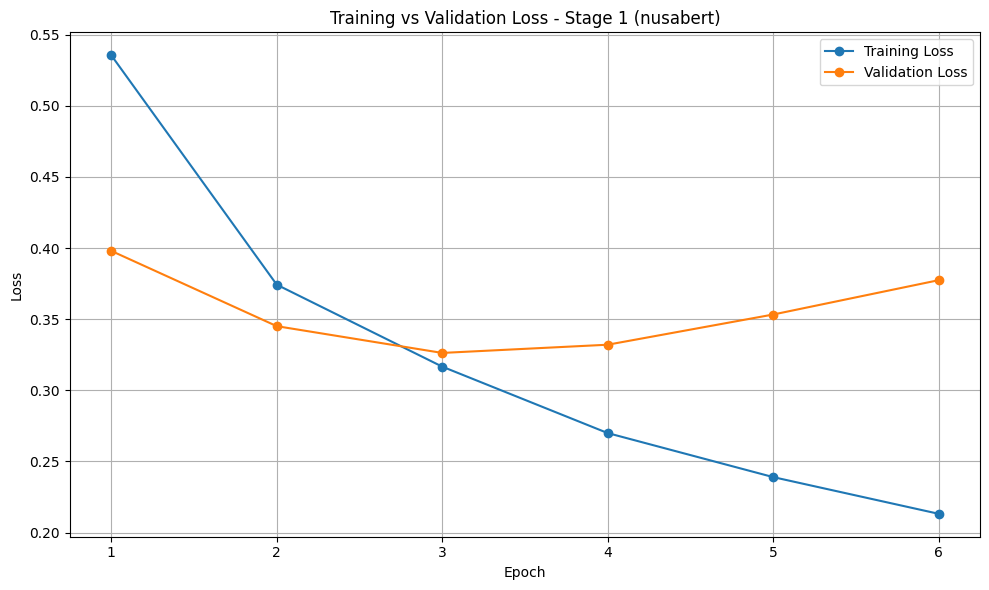

In [34]:
import matplotlib.pyplot as plt

history_s1 = trainer_s1.state.log_history

# Training loss rata-rata per epoch
train_logs_s1 = [x for x in history_s1 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

epoch_numbers_s1 = sorted(set(int(np.ceil(e)) for e in train_epochs_s1))
avg_train_loss_s1 = [
    np.mean([l for e, l in zip(train_epochs_s1, train_losses_s1) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s1
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s1 = {}
for x in history_s1:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s1:
            val_loss_by_epoch_s1[ep] = x['eval_loss']
val_epochs_s1 = sorted(val_loss_by_epoch_s1)
val_losses_s1 = [val_loss_by_epoch_s1[ep] for ep in val_epochs_s1]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s1, avg_train_loss_s1, marker='o', label='Training Loss')
plt.plot(val_epochs_s1, val_losses_s1, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 1 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

probs1_test = torch.softmax(torch.tensor(pred1.predictions), dim=-1)[:, 1].numpy()
# pred_label1_tuned = (probs1_test >= best_threshold_s1).astype(int)

print("Stage 1 classification report @ default threshold (0.5) -- test set:")
print(classification_report(y_test, pred_label1))

# print(f"\nStage 1 classification report @ tuned threshold ({best_threshold_s1:.4f}) -- test set:")
# print(classification_report(y_test, pred_label1_tuned))

Stage 1 classification report @ default threshold (0.5) -- test set:
              precision    recall  f1-score   support

           0       0.94      0.89      0.91      5532
           1       0.71      0.82      0.76      1844

    accuracy                           0.87      7376
   macro avg       0.82      0.85      0.84      7376
weighted avg       0.88      0.87      0.87      7376



In [36]:
print(f"ROC-AUC (test): {roc_auc_score(y_test, probs1_test):.4f}")
print(f"PR-AUC  (test): {average_precision_score(y_test, probs1_test):.4f}\n")

ROC-AUC (test): 0.9375
PR-AUC  (test): 0.8379



In [37]:
import json

history_s1 = trainer_s1.state.log_history

with open("training_progress_s1.json", "w") as f:
    json.dump(history_s1, f, indent=4)

print("Training progress saved to training_progress_s1.json")

Training progress saved to training_progress_s1.json


<Axes: >

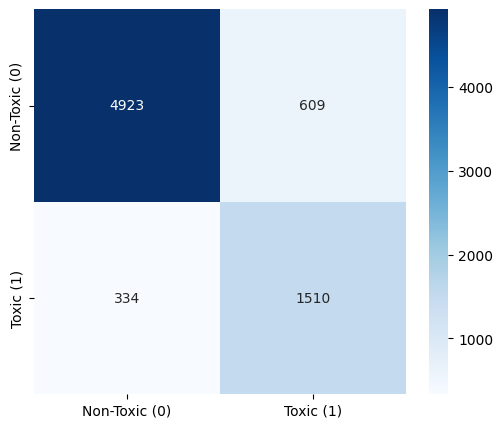

In [38]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
# Confusion matrix
cm_s1 = confusion_matrix(y_test, pred_label1)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_s1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Toxic (0)", "Toxic (1)"],
    yticklabels=["Non-Toxic (0)", "Toxic (1)"]
)